In [1]:
'''
check snr vs amplitude for efficiency data
'''

'\ncheck snr vs amplitude for efficiency data\n'

In [3]:
import os
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm

import glob
import os
import numpy as np
import pandas as pd
from tqdm import tqdm


import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
# from tensorflow import keras
import get_postage_stamps as gpsf
from scipy.ndimage import sobel
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [4]:
#adding some cells here just to do this calculation for size 1
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/df_implants_neg")
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/df_implants_pos")

In [20]:
!ls /lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/lightcurves_neg_filtered

lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0043_1701_filtered_hap2.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0043_1701_filtered_hap3.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0068_1335_filtered_hap2.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0068_1335_filtered_hap3.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0095_0100_filtered_hap2.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0095_0100_filtered_hap3.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0130_2402_filtered_hap2.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0130_2402_filtered_hap3.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0198_1618_filtered_hap2.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0198_1618_filtered_hap3.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0209_2151_filtered_hap2.csv
lightcurve_ztf_20221020138241_00

In [5]:
df_implants_neg

,Unnamed: 0,filename,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quad_from_implant
0,0,ztf_20221020294271_000449_zr_c04_x_0004.,424.0,113.0,0.950,7.0,3
1,1,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,696.0,0.600,6.0,3
2,2,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,1199.0,0.990,9.0,3
3,3,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,1840.0,0.400,7.0,3
4,4,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,2410.0,0.600,5.0,3
...,...,...,...,...,...,...,...
795,795,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,120.0,0.950,5.0,3
796,796,ztf_20221020154120_000640_zi_c03_x_0002.,3000.0,685.0,0.995,4.0,3
797,797,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,1240.0,0.950,4.0,3
798,798,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,1843.0,0.400,7.0,3


In [41]:
np.max(df_implants_neg["col_from_implant"]), np.max(df_implants_neg["row_from_implant"])

(2454.0, 3000.0)

In [23]:
test_lc = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/lightcurves_neg_filtered/lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._1.npy_1_0043_1701_filtered_hap2.csv")

In [34]:

find_lightcurve(NEG_DIR, df_implants_neg.loc[0]['filename'], df_implants_neg.loc[0]['quad_from_implant'], df_implants_neg.loc[0]['col_from_implant'])

/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/lightcurves_neg_filtered/lightcurve_ztf_20221020294271_000449_zr_c04_x_0004._3.npy_3_0113_*_filtered_hap2.csv


[]

In [17]:
%matplotlib inline

In [24]:
test_lc

,Unnamed: 0,flux_hap_2
0,0,0.042300
1,1,0.032722
2,2,0.034263
3,3,0.026311
4,4,0.037197
...,...,...
3075,3075,0.035126
3076,3076,0.027283
3077,3077,0.034404
3078,3078,0.051863


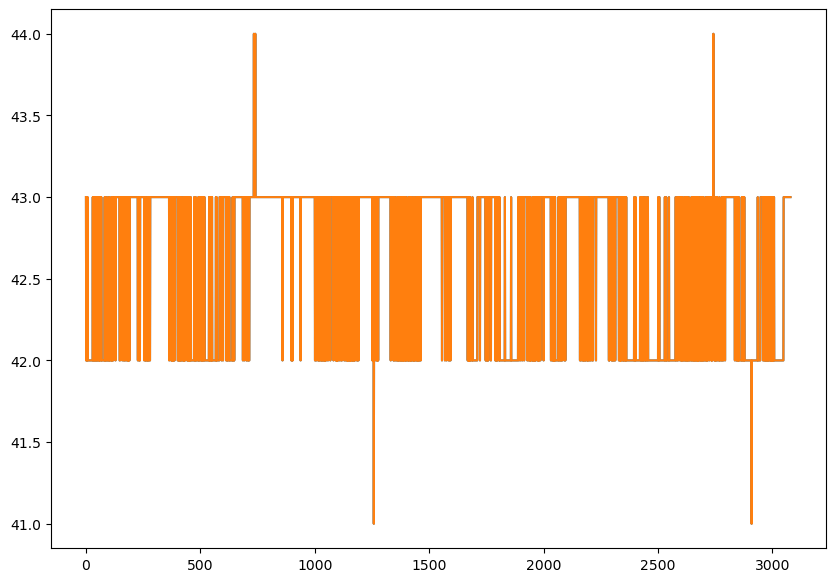

In [18]:
plt.plot(test_lc['max_col'])
plt.show()

In [42]:


NEG_DIR = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/lightcurves_neg_filtered"
# adjust to wherever the positive light curves live:
POS_DIR = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/lightcurves_pos_filtered"

out_cols = ["snr_local", "snr_global", "noise_local", "noise_global",
            "local_average_outside", "height", "FWHM", "signal_local",
            "tallest_index_absolute", "point_left", "point_right"]

def find_lightcurve(data_dir, filename, quad, row):
    # y of the star is unknown/irrelevant, so wildcard it
    pattern = os.path.join(
        data_dir,
        f"lightcurve_{filename}_{int(quad)}.npy_{int(quad)}_{int(row):04d}_*_filtered_hap2.csv"
    )
    # print(pattern)
    matches = glob.glob(pattern)
    return matches

def measure_snr_df(df, data_dir, is_neg):
    """
    is_neg=True negative injections, False for the pos injections
    """
    cache = {}   # path -> lightcurve array, so each file is read once
    results = []
    for idx, r in tqdm(df.iterrows(), total=len(df)):
        res = dict.fromkeys(out_cols, np.nan)
        res["lc_path"] = None
        res["status"] = "ok"
        try:
            matches = find_lightcurve(data_dir, r["filename"], r["quad_from_implant"], r["row_from_implant"])
            if len(matches) == 0:
                res["status"] = "no file"
            else:
                if len(matches) > 1:
                    res["status"] = f"{len(matches)} files matched, used first"
                path = sorted(matches)[0]
                res["lc_path"] = path
                if path not in cache:
                    cache[path] = pd.read_csv(path)["flux_hap_2"].to_numpy()
                tot = cache[path]
                row = int(r["row_from_implant"])
                if is_neg:
                    out = rff.get_snr_dimmest(tot, np.array([row]))
                else:
                    out = rff.get_snr_brightest(tot, np.array([row]))
                res.update(dict(zip(out_cols, out)))
        except Exception as e:
            res["status"] = f"error: {e!r}"
        results.append(res)

    return pd.concat([df.reset_index(drop=True), pd.DataFrame(results)], axis=1)

df_implants_neg_snr = measure_snr_df(df_implants_neg, NEG_DIR, is_neg=True)
df_implants_pos_snr = measure_snr_df(df_implants_pos, POS_DIR, is_neg=False)

print(df_implants_neg_snr["status"].value_counts())

100%|██████████| 800/800 [00:01<00:00, 437.81it/s]

ok         427
no file    373
Name: status, dtype: int64


In [43]:
print(df_implants_pos_snr["status"].value_counts())

ok         420
no file    380
Name: status, dtype: int64


In [44]:
df_implants_neg_snr

,Unnamed: 0,filename,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quad_from_implant,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,tallest_index_absolute,point_left,point_right,lc_path,status
0,0,ztf_20221020294271_000449_zr_c04_x_0004.,424.0,113.0,0.950,7.0,3,15.779142,9.455926,0.005472,0.009131,0.190185,-0.007455,1.0,0.086340,430.0,430.0,431.0,/lustre/lrspec/ZTF_data/efficiency_testing/nos...,ok
1,1,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,696.0,0.600,6.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,no file
2,2,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,1199.0,0.990,9.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,no file
3,3,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,1840.0,0.400,7.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,no file
4,4,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,2410.0,0.600,5.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,no file
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,795,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,120.0,0.950,5.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,no file
796,796,ztf_20221020154120_000640_zi_c03_x_0002.,3000.0,685.0,0.995,4.0,3,15.609962,10.033884,0.007608,0.011835,0.170981,-0.014102,1.0,0.118753,2992.0,2992.0,2993.0,/lustre/lrspec/ZTF_data/efficiency_testing/nos...,ok
797,797,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,1240.0,0.950,4.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,no file
798,798,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,1843.0,0.400,7.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,no file


In [48]:
import os, re
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import tqdm

NEG_DIR = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/lightcurves_neg_filtered"
POS_DIR = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/lightcurves_pos_filtered"  # adjust

out_cols = ["snr_local", "snr_global", "noise_local", "noise_global",
            "local_average_outside", "height", "FWHM", "signal_local",
            "tallest_index_absolute", "point_left", "point_right"]

# lightcurve_<filename incl. trailing '.'>_<quad>.npy_<quad>_<col>_<y>_filtered_hap2.csv
LC_RE = re.compile(r"^lightcurve_(?P<fname>.+\.)_(?P<q1>\d+)\.npy_(?P<q2>\d+)_(?P<col>\d+)_(?P<y>\d+)_filtered_hap2\.csv$")

def build_index(data_dir):
    """(filename, quad) -> list of (col, y, path)"""
    index = defaultdict(list)
    n_bad = 0
    with os.scandir(data_dir) as it:
        for entry in it:
            m = LC_RE.match(entry.name)
            if not m:
                n_bad += 1
                continue
            index[(m["fname"], int(m["q2"]))].append((int(m["col"]), int(m["y"]), entry.path))
    print(f"Indexed {sum(len(v) for v in index.values())} files "
          f"({n_bad} names didn't match the regex)")
    return index

def find_lightcurve(index, filename, quad, col, tol=5):
    """Return (path, matched_col, status). Nearest col within +/- tol."""
    cands = index.get((filename, int(quad)), [])
    cands = [c for c in cands if abs(c[0] - int(col)) <= tol]
    if not cands:
        return None, None, "no file"
    dmin = min(abs(c[0] - int(col)) for c in cands)
    best = sorted([c for c in cands if abs(c[0] - int(col)) == dmin], key=lambda c: c[2])
    status = "ok"
    if len(best) > 1:
        status = f"{len(best)} files tied at dcol={dmin}, used first"
    elif len(cands) > 1:
        status = f"{len(cands)} files within +/-{tol}, used nearest"
    return best[0][2], best[0][0], status

def measure_snr_df(df, data_dir, flip_sign=False, tol=5):
    index = build_index(data_dir)
    cache = {}
    results = []
    for _, r in tqdm(df.iterrows(), total=len(df)):
        res = dict.fromkeys(out_cols, np.nan)
        res.update(lc_path=None, matched_col=np.nan, dcol=np.nan, status="ok")
        try:
            path, mcol, status = find_lightcurve(index, r["filename"], r["quad_from_implant"],
                                                 r["row_from_implant"], tol=tol)
            res["status"] = status
            if path is not None:
                res["lc_path"] = path
                res["matched_col"] = mcol
                res["dcol"] = mcol - int(r["row_from_implant"])
                if path not in cache:
                    cache[path] = pd.read_csv(path)["flux_hap_2"].to_numpy()
                tot = cache[path]
                if flip_sign:
                    out = rff.get_snr_brightest(tot, np.array([int(r["col_from_implant"])]))
                else:
                    out = rff.get_snr_dimmest(tot, np.array([int(r["col_from_implant"])]))
                res.update(dict(zip(out_cols, out)))
        except Exception as e:
            res["status"] = f"error: {e!r}"
        results.append(res)
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(results)], axis=1)

df_implants_neg_snr = measure_snr_df(df_implants_neg, NEG_DIR, flip_sign=False, tol=5)
df_implants_pos_snr = measure_snr_df(df_implants_pos, POS_DIR, flip_sign=True, tol=5)

print(df_implants_neg_snr["status"].value_counts())
print(df_implants_neg_snr["dcol"].value_counts().sort_index())

Indexed 820 files (820 names didn't match the regex)


100%|██████████| 800/800 [00:00<00:00, 1746.28it/s]


Indexed 820 files (820 names didn't match the regex)


100%|██████████| 800/800 [00:00<00:00, 1691.72it/s]

ok         780
no file     20
Name: status, dtype: int64
-4.0      6
-2.0      2
-1.0    135
 0.0    427
 1.0    204
 2.0      4
 4.0      2
Name: dcol, dtype: int64


In [49]:
print(df_implants_pos_snr["status"].value_counts())

ok         780
no file     20
Name: status, dtype: int64


In [52]:
np.min(df_implants_pos_snr['snr_global'])

-3.201749008557749

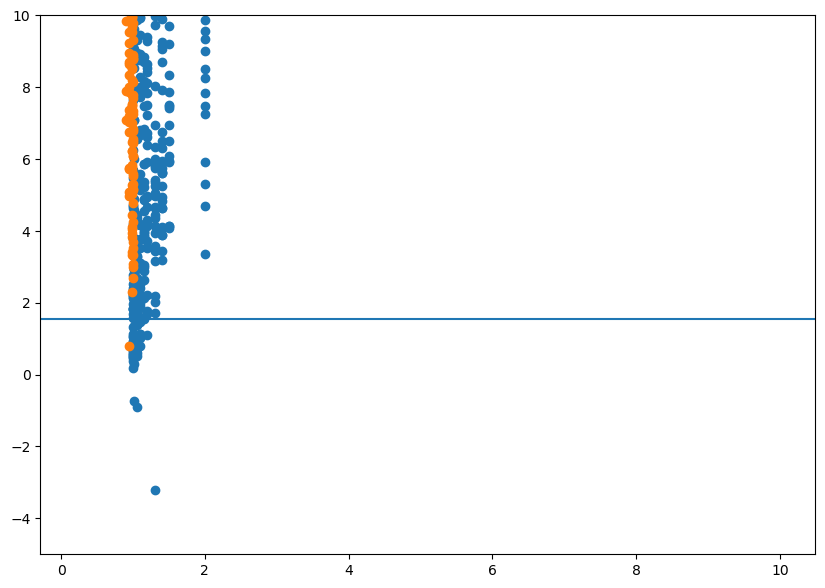

In [56]:
plt.scatter(df_implants_pos_snr['A_from_implant'],df_implants_pos_snr['snr_global'])
plt.scatter(df_implants_neg_snr['A_from_implant'],df_implants_neg_snr['snr_global'])
plt.ylim(-5,10)
plt.axhline(1.55)

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

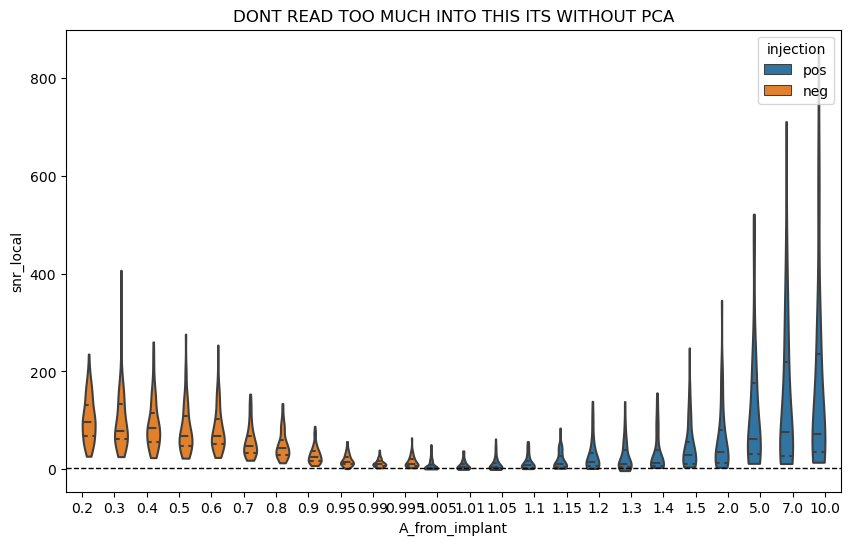

In [63]:


a = df_implants_pos_snr.assign(kind="pos")
b = df_implants_neg_snr.assign(kind="neg")
df_plot = pd.concat([a, b], ignore_index=True)
df_plot = df_plot[df_plot["snr_local"].notna()]

order = sorted(df_plot["A_from_implant"].unique())

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(
    data=df_plot, x="A_from_implant", y="snr_global", hue="kind",
    order=order, hue_order=["pos", "neg"],
    split=False, inner="quartile", cut=0, density_norm="count", ax=ax,
)
ax.axhline(1.55, color="k", ls="--", lw=1)
# ax.set_ylim(-5, 10)
ax.set_xlabel("A_from_implant")
ax.set_ylabel("snr_local")
ax.legend(title="injection")
plt.title("DONT READ TOO MUCH INTO THIS ITS WITHOUT PCA")
plt.show()

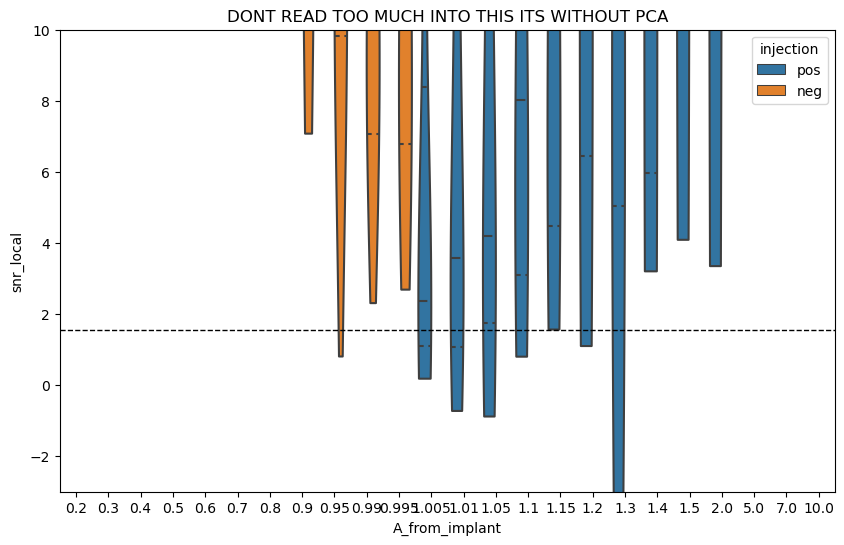

In [70]:


a = df_implants_pos_snr.assign(kind="pos")
b = df_implants_neg_snr.assign(kind="neg")
df_plot = pd.concat([a, b], ignore_index=True)
df_plot = df_plot[df_plot["snr_local"].notna()]

order = sorted(df_plot["A_from_implant"].unique())

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(
    data=df_plot, x="A_from_implant", y="snr_global", hue="kind",
    order=order, hue_order=["pos", "neg"],
    split=False, inner="quartile", cut=0, density_norm="count", ax=ax,
)
ax.axhline(1.55, color="k", ls="--", lw=1)
ax.set_ylim(-3,10)
ax.set_xlabel("A_from_implant")
ax.set_ylabel("snr_local")
ax.legend(title="injection")
plt.title("DONT READ TOO MUCH INTO THIS ITS WITHOUT PCA")
plt.show()

In [ ]:
#okay so that was all fun and everything but i think we need 
#it to be PCA'd, filtered, and maybe de-duplicated
#which i think does mean we need new injections that are just one per

In [72]:
np.nanmean(df_implants_pos_snr["noise_global"])

0.12244462593620259

In [73]:
np.nanmean(df_implants_pos_snr["height"])

0.7068118857967102

In [74]:
np.nanmean(df_implants_pos_snr["local_average_outside"])

0.5297307433381897

In [75]:
np.nanmean(df_implants_pos_snr["FWHM"])

8.307692307692308

In [76]:
!ls -f "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/lightcurves_pos_filtered"  | head -10


.
..
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._3.npy_3_3012_2651_filtered_hap2.csv
lightcurve_ztf_20221020148032_000686_zg_c02_x_0001._4.npy_4_0708_1530_filtered_hap3.csv
lightcurve_ztf_20221020148032_000686_zg_c02_x_0001._3.npy_3_0886_1548_filtered_hap3.csv
lightcurve_ztf_20221020148032_000686_zg_c02_x_0001._2.npy_2_0441_0281_filtered_hap2.csv
lightcurve_ztf_20221020148032_000686_zg_c02_x_0001._2.npy_2_1759_2781_filtered_hap2.csv
lightcurve_ztf_20221020148032_000686_zg_c02_x_0001._1.npy_1_0378_1851_filtered_hap2.csv
lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._3.npy_3_2718_2110_filtered_hap3.csv
lightcurve_ztf_20221020148032_000686_zg_c02_x_0001._1.npy_1_3044_0246_filtered_hap3.csv
ls: write error: Broken pipe


In [79]:
POS_DIR = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/lightcurves_pos_filtered/"


In [80]:

pd.read_csv(POS_DIR+'lightcurve_ztf_20221020138241_000686_zi_c05_x_0000._3.npy_3_3012_2651_filtered_hap2.csv')

,Unnamed: 0,flux_hap_2
0,0,0.017425
1,1,0.019527
2,2,0.022147
3,3,0.018790
4,4,0.020733
...,...,...
3075,3075,0.020415
3076,3076,0.019304
3077,3077,0.019775
3078,3078,0.020816
